In [62]:
import datetime
import warnings
from rocketpy import Environment, Flight, Rocket, HybridMotor, Parachute, Function, Fluid, CylindricalTank, MassFlowRateBasedTank
from rocketpy.simulation import FlightDataExporter
from rocketpy.plots.compare import CompareFlights # allows for comparing data between different rocketpy flight objects and visualizing them
from rocketpy.simulation import FlightComparator, FlightDataImporter # allows for comparing data between a rocketpy flight and external data
from rocketpy.utilities import fin_flutter_analysis # only works with trapezoidal fins i think and i'm not sure how accurate it is yet
from fin_flutter import get_flutter_velocity

In [63]:
DISPLAY_EXTRA_INFO: bool = True                         # If each component of the Flight and Rocket should display information on it, like Environment and Motor data
USE_WEATHER_FORECAST: bool = False                      # If the environment should be manually set, or set by the predicted weather conditions using GFS (data for November 7 not available until October 23)
SENSOR_REFRESH_RATE: int = 100                          # Hz - Rate at which the trigger function is ran to deploy a parachute (simulating onboard sensors)
COMPARISON_SIM_PATH: str | None = None                  # The path to the csv sim file of a reference simulation to compare this simulation to (None for no comparison). Keep exported data in SI units
EXPORT_FLIGHT_PATH: str | None = None                   # The path to where the KML file of the flight path should be stored (None for don't export). This file can be imported into Google Earth to view the flight path
ANIMATE_TRAJECTORY: bool = True                         # If a window should be opened to show an animation representing the full flight path
PLAYBACK_SPEED: float = 1.0                             # The speed at which the visual flight simulation should start at (can be changed while viewing)
TIME_STEP: float = 0.03                                 # Seconds per frame in the visual flight simulation
STOP_AT_APOGEE: bool = False                            # If the flight should stop being simulated when reaching apogee
CAMERA_MODE: str = "static"                             # "static", "follow", "ground", or "body" - Manages how the camera moves in the visual flight simulation
COLOR_BY: str = "speed"                                 # "speed", "mach", "dynamic_pressure", "acceleration", "altitude", or None - Colors the path of the rocket depending on this value (in the visual flight simulation)


Gravity Details

Acceleration of gravity at surface level:    9.8071 m/s²
Acceleration of gravity at  80.000 km (ASL): 9.5676 m/s²


Launch Site Details

Launch Date: 2026-10-29 12:00:00 UTC
Launch Site Latitude: 49.00000°
Launch Site Longitude: 81.00000°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 500000.00 E    5427455.78 N
Launch Site UTM zone: 44U
Launch Site Surface Elevation: 890.0 m


Atmospheric Model Details

Atmospheric Model Type: custom_atmosphere
custom_atmosphere Maximum Height: 80.000 km

Surface Atmospheric Conditions

Surface Wind Speed: 2.24 m/s
Surface Wind Direction: 243.43°
Surface Wind Heading: 63.43°
Surface Pressure: 910.77 hPa
Surface Temperature: 282.37 K
Surface Air Density: 1.124 kg/m³
Surface Speed of Sound: 336.64 m/s


Earth Model Details

Earth Radius at Launch site: 6366.00 km
Semi-major Axis: 6378.14 km
Semi-minor Axis: 6356.75 km
Flattening: 0.0034



Gravity Model Plots


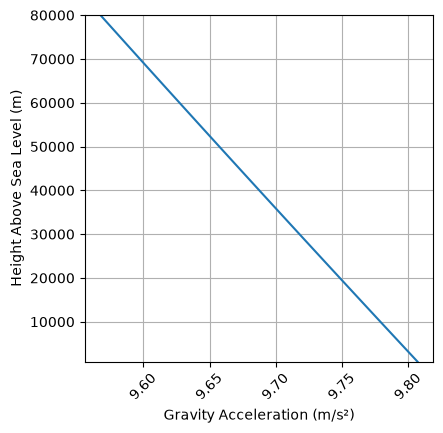



Atmospheric Model Plots


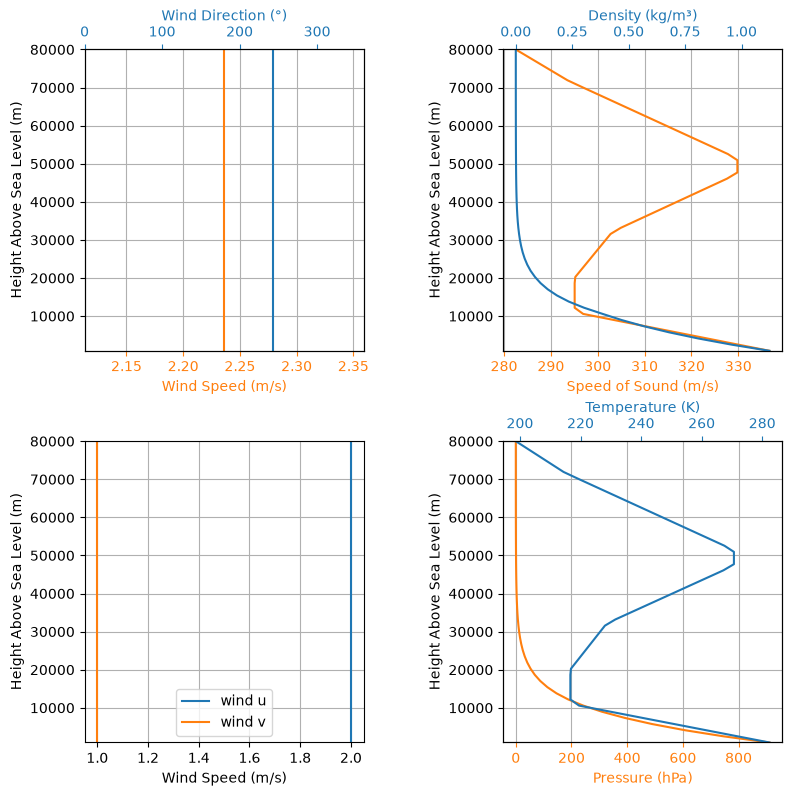

In [64]:
env = Environment(elevation=890, latitude=49, longitude=81)
tomorrow = datetime.date.today() + datetime.timedelta(days=1)
env.set_date((tomorrow.year, tomorrow.month, tomorrow.day, 12))
if USE_WEATHER_FORECAST:
    env.set_atmospheric_model(
        type="forecast",
        file="GFS"
    )
else:
    env.set_atmospheric_model(
        type="custom_atmosphere",
        wind_u = 2,
        wind_v=1,
    )
if DISPLAY_EXTRA_INFO:
    env.all_info()
del tomorrow

In [65]:
# cgs here are relative to their components like in MAPLEAF
current_position = 0
component_data = {}
component_data["nose_cone_shell+coupler"] = {
    "mass": 1.75,
    "position": current_position,
    "cg": -0.7159,
    "length": 0.6179,
    "base_diameter": 0.167,
    "kind": "lvhaack",
}
component_data["nose_cone_tip"] = {
    "mass": 0.5,
    "position": current_position, # relative to top of nose cone
    "cg": -0.081,
    "moi": (0.0004, 0.0004, 0.0002),
}
current_position -= component_data["nose_cone_shell+coupler"]["length"]

component_data["nose_cone_tube"] = {
    "mass": 0, # included in nose_cone_shell+coupler
    "position": current_position, # relative to top of nose cone
    "cg": -0.03175,
    "length": 0.0635,
    "outer_diameter": 0.167,
}
current_position -= component_data["nose_cone_tube"]["length"]

component_data["recovery_tube"] = {
    "mass": 0.9,
    "position": current_position,
    "cg": -0.154305,
    "length": 0.31242,
    "outer_diameter": 0.167,
}
current_position -= component_data["recovery_tube"]["length"]

component_data["payload_tube"] = {
    "mass": 0.4,
    "position": current_position,
    "cg": -0.135,
    "length": 0.27,
    "outer_diameter": 0.167,
}
component_data["payload"] = {
    "mass": 3,
    "position": current_position,
    "cg": -0.135,
    "moi": (0.0125, 0.0125, 0.005),
}
current_position -= component_data["payload_tube"]["length"]

component_data["camera_bulkhead"] = {
    "mass": 0.5,
    "position": current_position,
    "cg": -0.04064,
    "length": 0.08128,
    "outer_diameter": 0.167,
}
current_position -= component_data["camera_bulkhead"]["length"]

component_data["air_brakes_tube"] = {
    "mass": 1.1,
    "position": current_position,
    "cg": -0.04064,
    "length": 0.08128,
    "outer_diameter": 0.167,
}
component_data["air_brakes"] = {
    "mass": 1.727,
    "position": -1.36353,
    "cg": -0.4313,
    "moi": (0.0056, 0.00549, 0.00943),
}
current_position -= component_data["air_brakes_tube"]["length"]

component_data["avionics_tube+upper_plumbing"] = {
    "mass": 1.4,
    "position": current_position,
    "cg": -0.33655,
    "length": 0.6731,
    "outer_diameter": 0.167,
}
component_data["avionics"] = {
    "mass": 1.5,
    "position": -1.434904,
    "cg": -0.350796,
    "moi": (0.04804, 0.04921, 0.00845),
}
component_data["upper_plumbing"] = {
    "mass": 0.68,
    "position": -2.05503,
    "cg": -0,
    "moi": (0.00294, 0.00287, 0.00261),
}
current_position -= component_data["avionics_tube+upper_plumbing"]["length"]

component_data["upper_pv_casing"] = {
    "mass": 0.419,
    "position": current_position,
    "cg": -0.014186,
    "length": 0.009525,
    "outer_diameter": 0.167,
}
component_data["upper_pv_bulkhead"] = {
    "mass": 0.449,
    "position": -2.12126,
    "cg": -0,
    "moi": (0.00095, 0.00095, 0.00174),
}
current_position -= component_data["upper_pv_casing"]["length"]

component_data["pressure_vessel"] = {
    "mass": 5.7007,
    "position": current_position,
    "cg": -0.466725,
    "length": 0.93345,
    "outer_diameter": 0.167,
    "moi": (0.422204, 0.422204, 0.172753),
}
current_position -= component_data["pressure_vessel"]["length"]

component_data["lower_pv_casing"] = {
    "mass": 0.419,
    "position": current_position,
    "cg": -0.004576572,
    "length": 0.009525,
    "outer_diameter": 0.167,
}
component_data["lower_pv_bulkhead"] = {
    "mass": 0.4846,
    "position": -2.89396,
    "cg": -0,
    "moi": (0.00097, 0.00097, 0.00170),
}
current_position -= component_data["lower_pv_casing"]["length"]

component_data["lower_plumbing_tube"] = {
    "mass": 0.95,
    "position": current_position,
    "cg": -0.1397,
    "length": 0.2794,
    "outer_diameter": 0.167,
}
current_position -= component_data["lower_plumbing_tube"]["length"]

component_data["fin_can+cc+motor_liner"] = {
    "mass": 2.65,
    "position": current_position,
    "cg": -0.32131,
    "length": 0.64262,
    "outer_diameter": 0.167,
}
component_data["lower_plumbing"] = {
    "mass": 2.765,
    "position": -0,
    "cg": -3.0333,
    "moi": (0.01179, 0.01223, 0.00261),
}
component_data["lower_injector_bulkhead"] = {
    "mass": 0.3585,
    "position": -3.09334,
    "cg": -0,
    "moi": (0.00057, 0.00057, 0.00104),
}
component_data["mixing_plate"] = {
    "mass": 0.263,
    "position": -3.61856,
    "cg": -0,
    "moi": (0.00033, 0.00033, 0.00064),
}
component_data["nozzle+housing"] = {
    "mass": 1.955,
    "position": -3.76656,
    "cg": -0,
    "moi": (0.00412, 0.00412, 0.00643),
}
component_data["delta_fins"] = {
    "mass": 0,
    "position": -3.5183,
    "cg": -0.075,
    "num_fins": 3,
    "cant_angle": 0,
    "sweep_angle": 53,
    "root_chord": 0.45,
    "tip_chord": 0.264,
    "span": 0.14,
    "thickness": 0.01,
    "sweep_length": 0.186,
    "type": "trapezoidal",
}
current_position -= component_data["fin_can+cc+motor_liner"]["length"]

component_data["ballast"] = {
    "mass": 0,
    "position": -0.46658,
    "cg": -0,
}
component_data["chutes"] = {
    "mass": 3.741,
    "position": -0.66808,
    "cg": -0.154305,
    "moi": (0.00567557453, 0.00567557453, 0.003367923348),
}

component_data["recovery_system"] = {
    # Mass and cg for this 'component' are derived from the mass and cg of each stage. This is not an actual component, but just combines all stages into one component
    "position": 0,
    "stages": [
        {
            "name": "drogue",
            "trigger": "apogee",
            "chute_area": 4.67,
            "cd": 0.970,
            "delay": 0.1,
            "mass": 1.415,
            "position": -0,
            "cg": -0.93818,
        },
        {
            "name": "main",
            "trigger": 1307.2, # altitude
            "chute_area": 18.679,
            "cd": 2.2,
            "delay": 0.1,
            "mass": 0,
            "position": -0,
            "cg": -0,
        },
    ],
}
del current_position

total_mass = 0
total_cg = 0
for stage in component_data["recovery_system"]["stages"]:
    mass = stage["mass"]
    total_mass += mass
    total_cg += mass * (stage["position"] + stage["cg"])
    del mass
total_cg /= total_mass
component_data["recovery_system"]["mass"] = total_mass
component_data["recovery_system"]["cg"] = total_cg
del total_mass, total_cg

launch_data = {
    "heading": 0,
    "rotation_angle": 2,
    "rail_length": 12.192,
}

def get_mass_without_motor() -> float:
    mass = 0
    for component, data in component_data.items():
        result = data.get("mass")
        if result is not None:
            mass += data["mass"]
        else:
            warnings.warn(f"{component} does not have a mass!")
    return mass

def get_center_of_mass_without_motor() -> float:
    total_mass = 0
    components = 0
    for component, data in component_data.items():
        position = data.get("position")
        cg = data.get("cg")
        mass = data.get("mass")
        if position is not None and cg is not None and mass is not None:
            components += mass * (position + cg) # mass * global cg
            total_mass += mass
        else:
            missing = [name for name, val in {"position": position, "cg": cg, "mass": mass}.items() if val is None]
            warnings.warn(f"{component} does not have a {" or ".join(missing)}!")
    return components / total_mass

def get_moment_of_inertia() -> tuple[float, float, float]:
    com = get_center_of_mass_without_motor()
    total_x = 0
    total_y = 0
    total_z = 0
    for component, data in component_data.items():
        moment = data.get("moi")
        mass = data["mass"]
        position = data["position"]
        if moment is None:
            print(f"{component} has no listed moi, treating it like a point mass (mass {mass}kg)")
            xMoment = mass * (abs(position - com) ** 2)
            moment = (xMoment, xMoment, 0)
        shifted_moment = (moment[0] + mass * (abs(position - com) ** 2), moment[1] + mass * (abs(position - com) ** 2), moment[2]) # Parallel axis theorem for x and y but z stays same
        total_x += shifted_moment[0]
        total_y += shifted_moment[1]
        total_z += shifted_moment[2]
    return (total_x, total_y, total_z)

def get_max_radius() -> float:
    max_diameter: float = 0
    for data in component_data.values():
        diameter = data.get("outer_diameter")
        if diameter and diameter > max_diameter:
            max_diameter = diameter
    return max_diameter / 2

In [66]:
eos = Rocket(
    radius=get_max_radius(),
    mass=get_mass_without_motor(),
    inertia=get_moment_of_inertia(),
    power_off_drag=0.5,
    power_on_drag=0.5,
    center_of_mass_without_motor=get_center_of_mass_without_motor(),
    coordinate_system_orientation="tail_to_nose",
)

nose_cone_shell+coupler has no listed moi, treating it like a point mass (mass 1.75kg)
nose_cone_tube has no listed moi, treating it like a point mass (mass 0kg)
recovery_tube has no listed moi, treating it like a point mass (mass 0.9kg)
payload_tube has no listed moi, treating it like a point mass (mass 0.4kg)
camera_bulkhead has no listed moi, treating it like a point mass (mass 0.5kg)
air_brakes_tube has no listed moi, treating it like a point mass (mass 1.1kg)
avionics_tube+upper_plumbing has no listed moi, treating it like a point mass (mass 1.4kg)
upper_pv_casing has no listed moi, treating it like a point mass (mass 0.419kg)
lower_pv_casing has no listed moi, treating it like a point mass (mass 0.419kg)
lower_plumbing_tube has no listed moi, treating it like a point mass (mass 0.95kg)
fin_can+cc+motor_liner has no listed moi, treating it like a point mass (mass 2.65kg)
delta_fins has no listed moi, treating it like a point mass (mass 0kg)
ballast has no listed moi, treating it l

In [67]:
motor_length = 0.62
motor_position = component_data["fin_can+cc+motor_liner"]["position"] - component_data["fin_can+cc+motor_liner"]["length"] + motor_length
motor = HybridMotor(
    thrust_source=r"thrust.csv",
    dry_mass=0,
    dry_inertia=(0, 0, 0), #! change this
    nozzle_radius=0.165 / 2, # temp value that is just grain outer radius
    grain_number=1,
    grain_density=915, # density of paraffin wax ranges from 900kg/m^3 to 930kg/m^3
    grain_outer_radius=0.165 / 2,
    grain_initial_inner_radius=0.1 / 2,
    grain_initial_height=0.29,
    grain_separation=0,
    grains_center_of_mass_position=-3.64796, # absolute position as motor is at position 0
    center_of_dry_mass_position=motor_position - motor_length / 2,
    nozzle_position=motor_position - motor_length,
    burn_time=None, # burn for full time defined by thrust.csv
    throat_radius=0.165 / 2 / 3, # temp value that is just 1/3 of grain outer radius
    interpolation_method="linear",
    coordinate_system_orientation="nozzle_to_combustion_chamber",
    only_radial_burn=False,
)
del motor_length


Tank 'Oxidizer tank' Data:

Tank Geometry:
Average radius 0.080 m
Bottom: -0.4065 m
Top: 0.4065 m
Total height: 0.813 m
Total volume: 0.016479 m^3

Tank 'Oxidizer tank' Fluid Parameters:

Liquid Fluid
Name: N20_liquid
Density: 785.0000 kg/m^3

Gas Fluid
Name: N2_gas
Density: 1.1650 kg/m^3

Tank 'Oxidizer tank' Mass Flux Data:

Initial Quantities at t = 0.00 s:
Initial Fluid Mass: 1.000e+01 kg
Initial Liquid Volume: 1.274e-02 m^3
Initial Liquid Level: 2.220e-01 m

Final Quantities at t = 5.95 s:
Final Fluid Mass: 4.100e-07 kg
Final Liquid Volume: 5.223e-10 m^3
Final Liquid Level: -4.065e-01 m


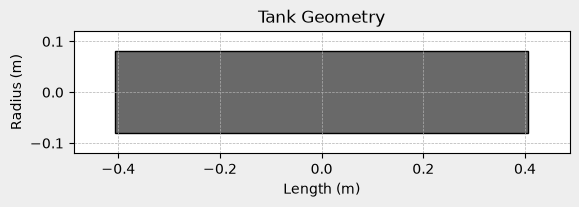

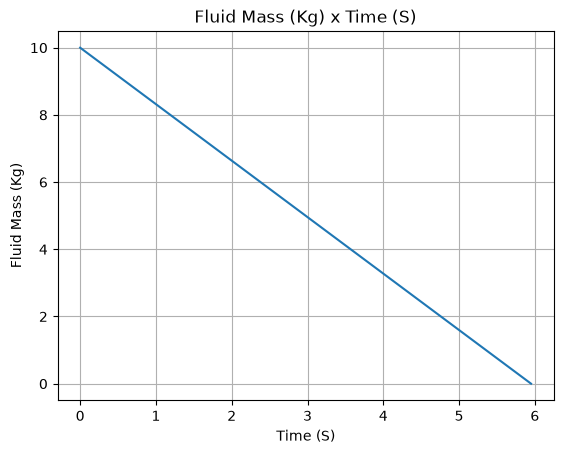

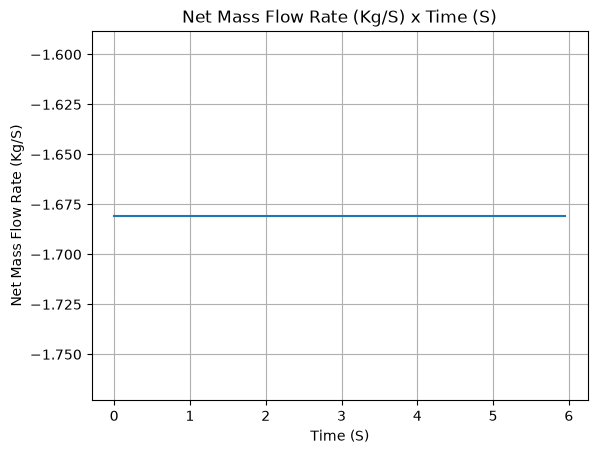

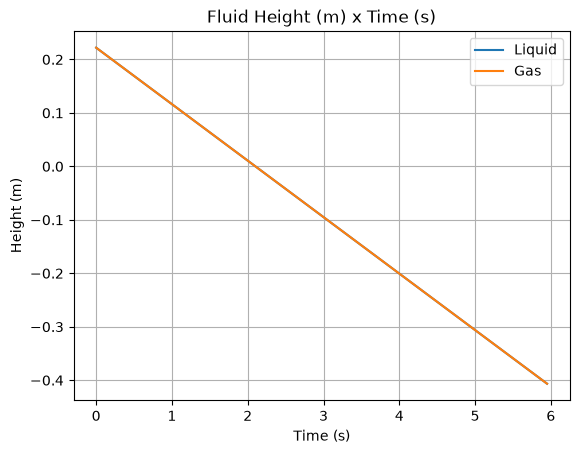

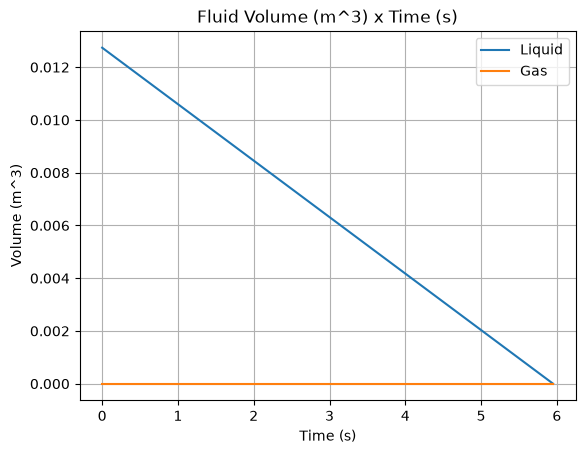

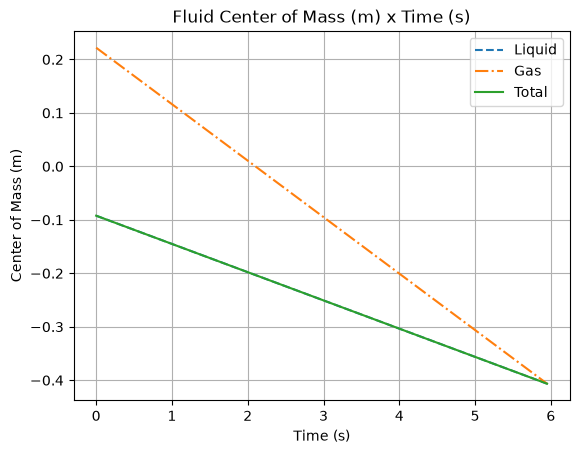

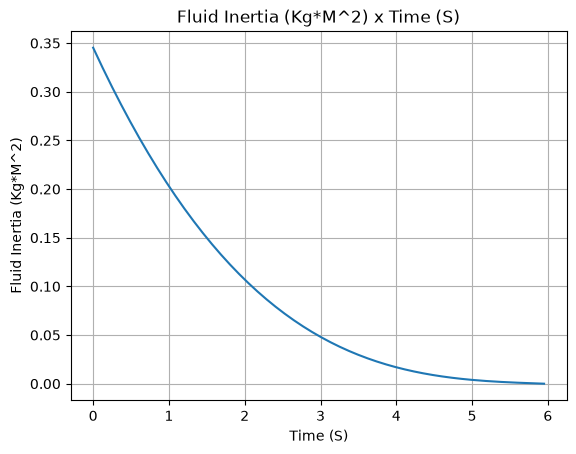

In [68]:
oxidizer_liquid = Fluid("N20_liquid", density=785) # kg/m^3 density from online search
oxidizer_gas = Fluid("N2_gas", density=1.165) # kg/m^3 density from online search
tank_shape = CylindricalTank(radius_function=0.16065 / 2, height=0.813)
tank = MassFlowRateBasedTank(
    name="Oxidizer tank",
    geometry=tank_shape,
    flux_time=motor.burn_duration,
    liquid=oxidizer_liquid,
    gas=oxidizer_gas,
    initial_liquid_mass=10, # from MAPLEAF
    initial_gas_mass=0, # treating all mass as liquid
    liquid_mass_flow_rate_in=0,
    gas_mass_flow_rate_in=0,
    liquid_mass_flow_rate_out=1.6806722,
    gas_mass_flow_rate_out=0,
)
del oxidizer_liquid, oxidizer_gas, tank_shape
motor.add_tank(tank=tank, position=-2.77796) # absolute position as motor is at position 0
if DISPLAY_EXTRA_INFO:
    tank.all_info()

Nozzle Details
Outlet Radius: 0.0825 m
Throat Radius: 0.0275 m
Outlet Area: 0.021382 m²
Throat Area: 0.002376 m²
Position: -3.9739999999999998 m

Grain Details
Number of Grains: 1
Grain Spacing: 0 m
Grain Density: 915 kg/m3
Grain Outer Radius: 0.0825 m
Grain Inner Radius: 0.05 m
Grain Height: 0.29 m
Grain Volume: 0.004 m3
Grain Mass: 3.590 kg

Motor Details
Total Burning Time: 5.9500000000000455 s
Total Propellant Mass: 13.590 kg
Structural Mass Ratio: 0.000
Average Propellant Exhaust Velocity: 1295.726 m/s
Average Thrust: 2959.434 N
Maximum Thrust: 3724.547680677063 N at 0.26500000000010004 s after ignition.
Total Impulse: 17608.631 Ns



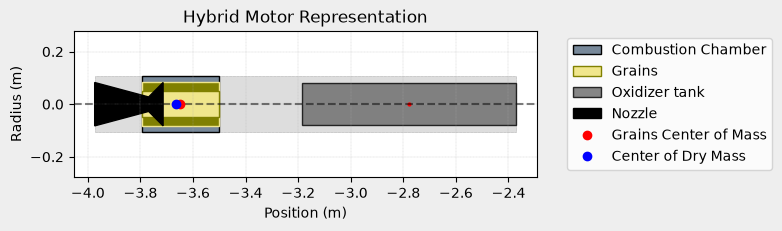

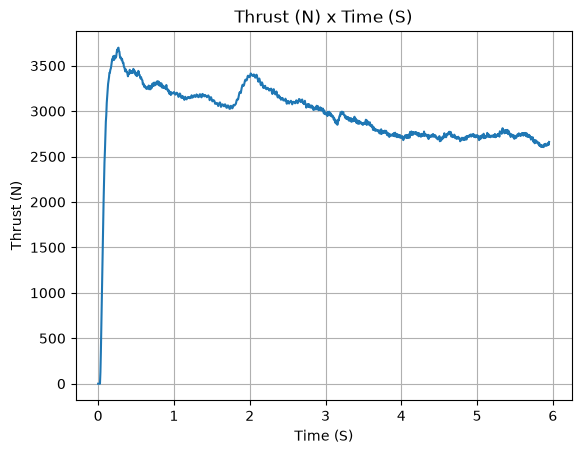

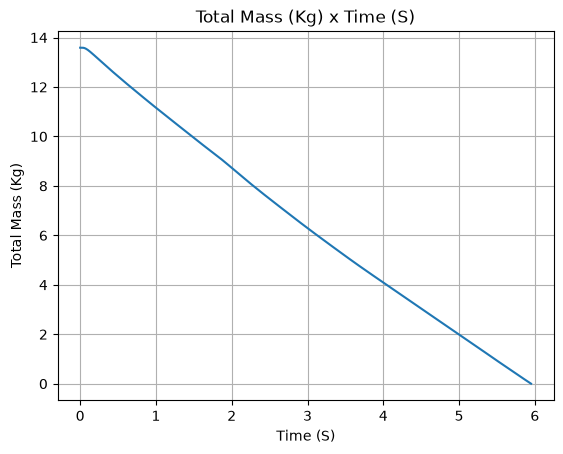

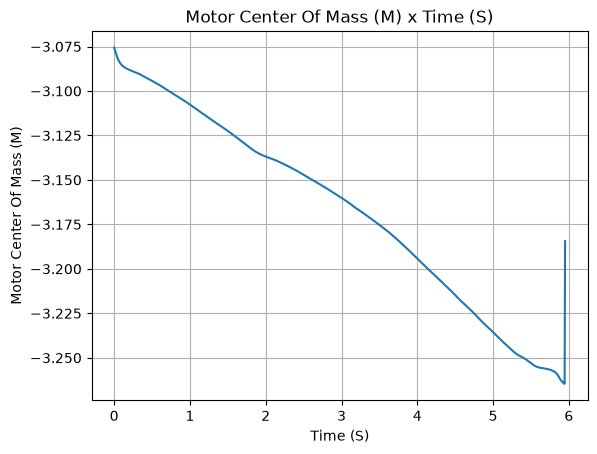

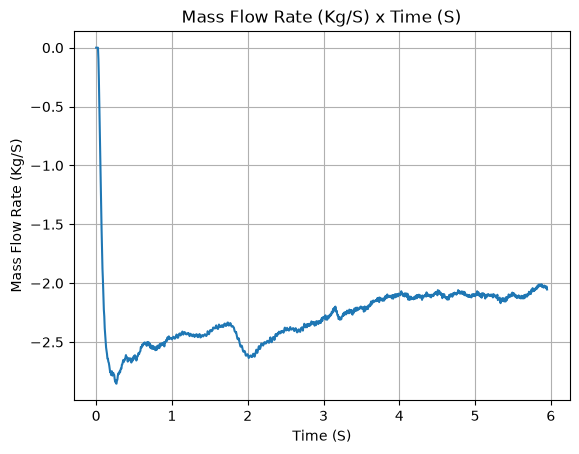

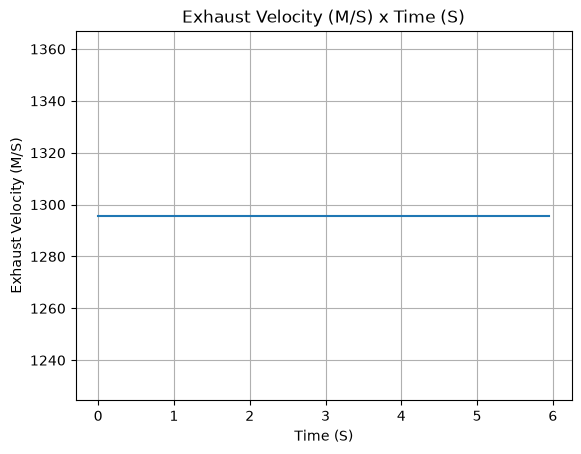

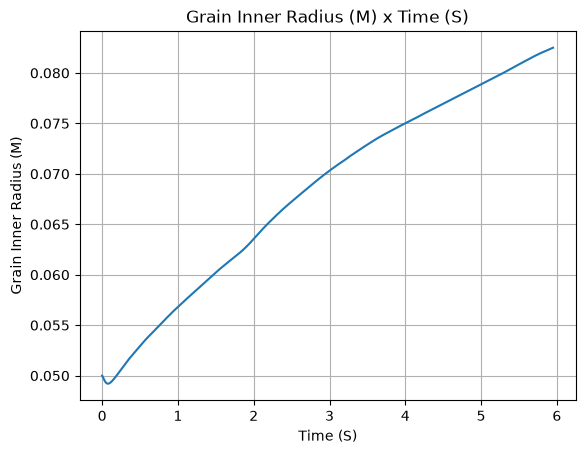

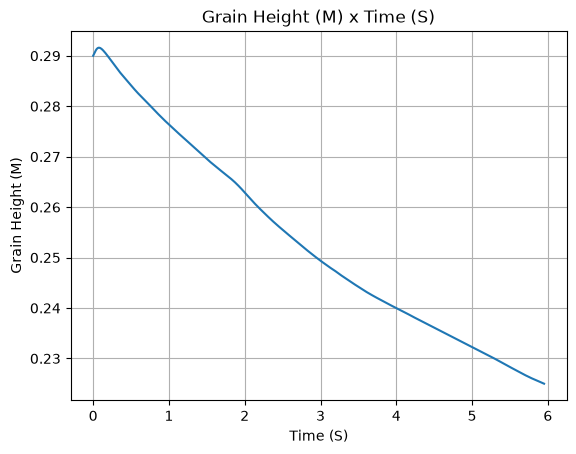

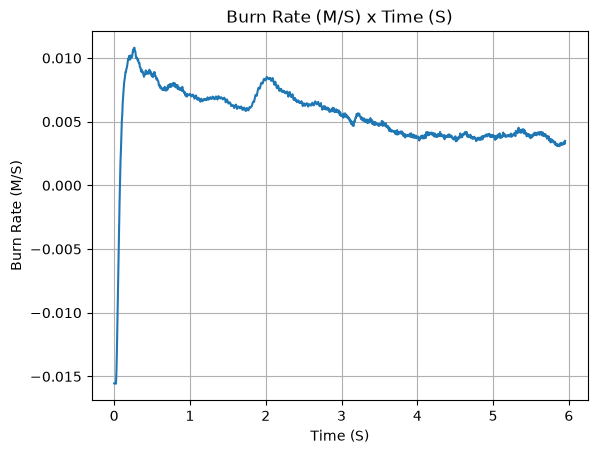

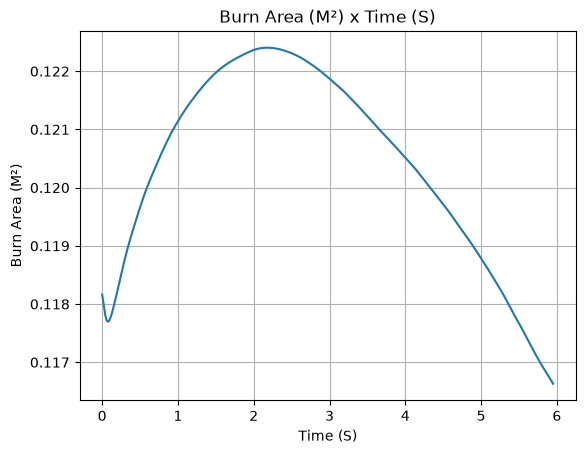

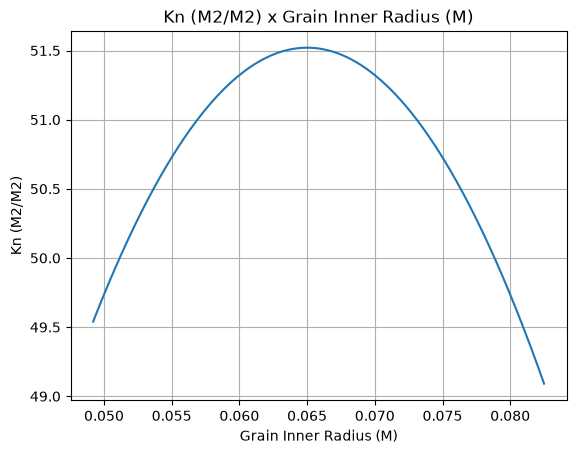

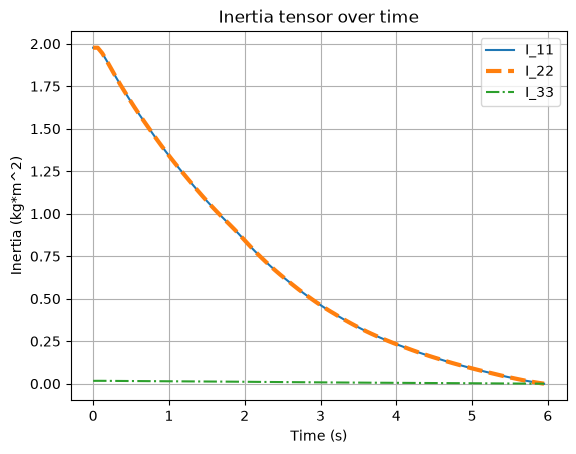

In [69]:
if DISPLAY_EXTRA_INFO:
    motor.all_info()
eos.add_motor(motor, position=0)

Geometric information of NoseCone:
----------------------------------
Length: 0.618 m
Kind: lvhaack
Base radius: 0.084 m
Reference rocket radius: 0.084 m
Reference radius ratio: 1.000

Lift information of the AeroSurface:
-----------------------------------
Center of Pressure position in local coordinates: (0.000, 0.000, 0.348)
Lift coefficient derivative at Mach 0 and AoA 0: 2.000 1/rad



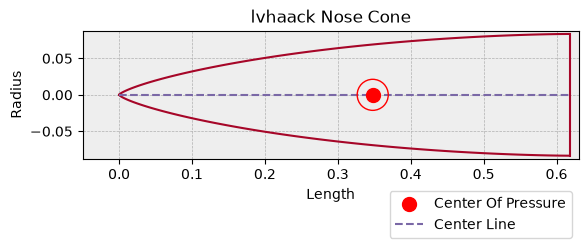

In [70]:
nose_cone = eos.add_nose(length=component_data["nose_cone_shell+coupler"]["length"], kind=component_data["nose_cone_shell+coupler"]["kind"], position=component_data["nose_cone_shell+coupler"]["position"])
if DISPLAY_EXTRA_INFO:
    nose_cone.info()
    nose_cone.plots.draw()

Geometric information of the fin set:
-------------------------------------
Number of fins: 3
Reference rocket radius: 0.084 m
Tip chord: 0.264 m
Root chord: 0.450 m
Span: 0.140 m
Cant angle: 0.000 ° or 0.000 rad
Longitudinal section area: 0.050 m²
Aspect ratio: 0.784 
Gamma_c: 0.586 m
Mean aerodynamic chord: 0.064 m

Lift information of the fin set:
--------------------------------
Lift interference factor: 1.374 m
Center of Pressure position in local coordinates: (0.000, 0.000, 0.176)
Lift Coefficient derivative (single fin) at Mach 0 and AoA 0: 2.671


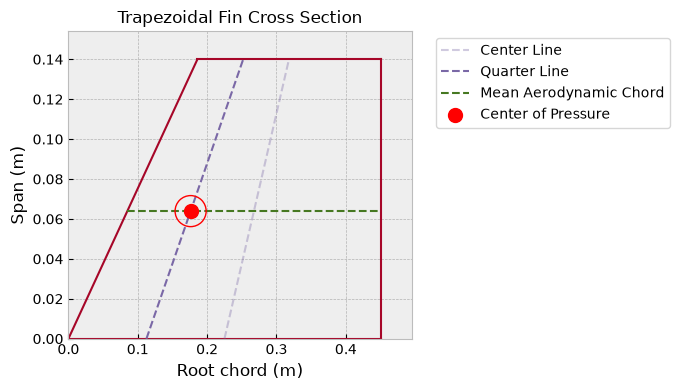

In [71]:
fin_data = component_data["delta_fins"]
fin_type = fin_data["type"]
fin_set = None
if fin_type == "free_form":
    fin_set = eos.add_free_form_fins(
        n=fin_data["num_fins"],
        position=fin_data["position"],
        shape_points=fin_data["shape_points"],
        cant_angle=0,
        airfoil=None,
    )
elif fin_type == "trapezoidal":
    fin_set = eos.add_trapezoidal_fins(
        n=fin_data["num_fins"],
        root_chord=fin_data["root_chord"],
        tip_chord=fin_data["tip_chord"],
        span=fin_data["span"],
        position=fin_data["position"],
        cant_angle=fin_data["cant_angle"],
        airfoil=None,
    )
if fin_set is None:
    raise RuntimeError(f"Fin type {fin_type} is undefined")

if DISPLAY_EXTRA_INFO:
    fin_set.info()
    fin_set.plots.draw()
del fin_data, fin_type

In [72]:
eos.parachutes.clear()
parachutes: list[Parachute] = []
for parachute_data in component_data["recovery_system"]["stages"]:
    parachute: Parachute = eos.add_parachute(
        name=parachute_data["name"],
        cd_s=parachute_data["cd"],
        trigger=parachute_data["trigger"],
        sampling_rate=SENSOR_REFRESH_RATE,
        lag=parachute_data["delay"],
        noise=(0, 0, 0),
    )
    if DISPLAY_EXTRA_INFO:
        parachute.info()
    parachutes.append(parachute)
    del parachute


Parachute Details

Parachute Drogue with a cd_s of 0.9700 m2
Ejection signal trigger: At Apogee
Ejection system refresh rate: 100.000 Hz
Time between ejection signal is triggered and the parachute is fully opened: 0.1 s


Parachute Details

Parachute Main with a cd_s of 2.2000 m2
Ejection signal trigger: 1307.2 m (AGL)
Ejection system refresh rate: 100.000 Hz
Time between ejection signal is triggered and the parachute is fully opened: 0.1 s



CG without motor: -2.050758984967739 m
CG with no propellant: -2.050758984967739 m
CG with propellant: -2.337251876368013 m

Inertia Details

Rocket Mass: 35.027 kg (without motor)
Rocket Dry Mass: 35.027 kg (with unloaded motor)
Rocket Loaded Mass: 48.617 kg
Rocket Structural Mass Ratio: 0.720
Rocket Inertia (with unloaded motor) 11: 78.413 kg*m2
Rocket Inertia (with unloaded motor) 22: 78.414 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.216 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.0835 m
Rocket Frontal Area: 0.021904 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.000 m
Rocket Center of Dry Mass - Nozzle Exit: 1.923 m
Rocket Center of Dry Mass - Center of Propellant Mass: 1.025 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.286 m


Aerodynamics Lift Coefficient Deri

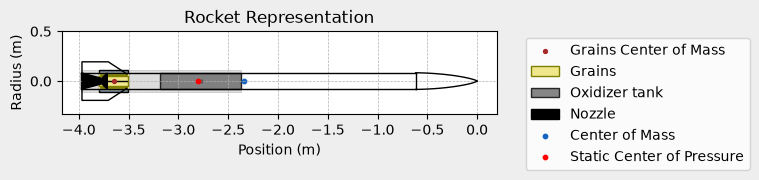


Mass Plots
----------------------------------------


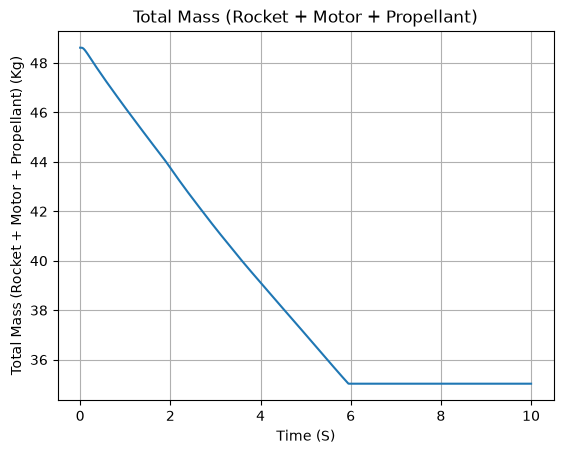

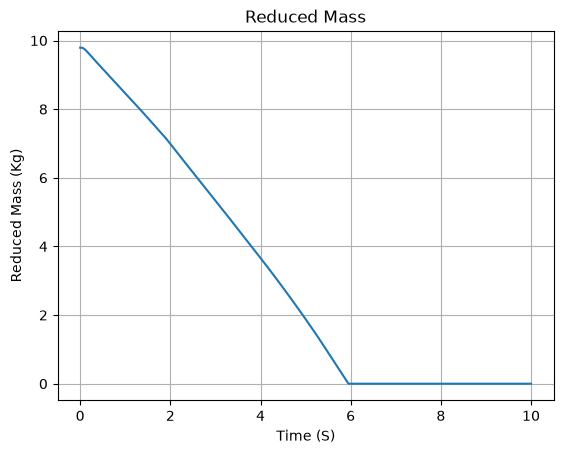


Aerodynamics Plots
----------------------------------------
Drag Plots
--------------------


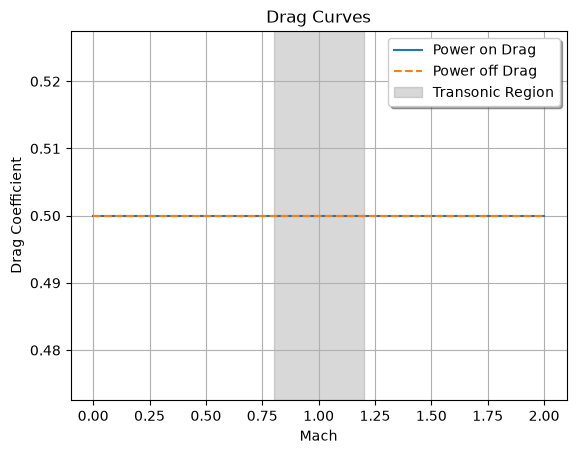


Stability Plots
--------------------


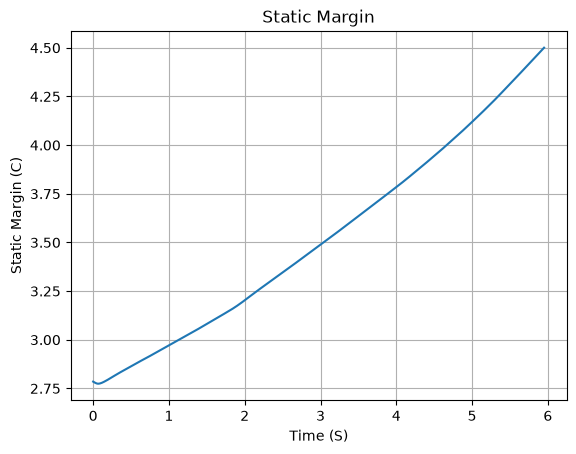

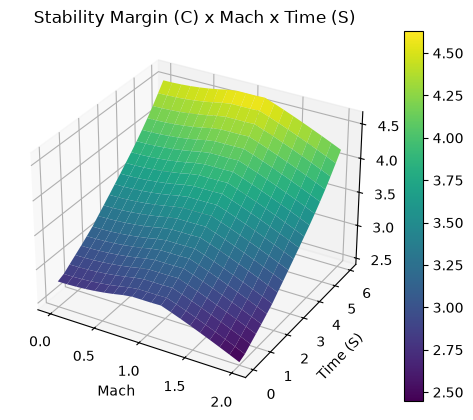


Thrust-to-Weight Plot
----------------------------------------


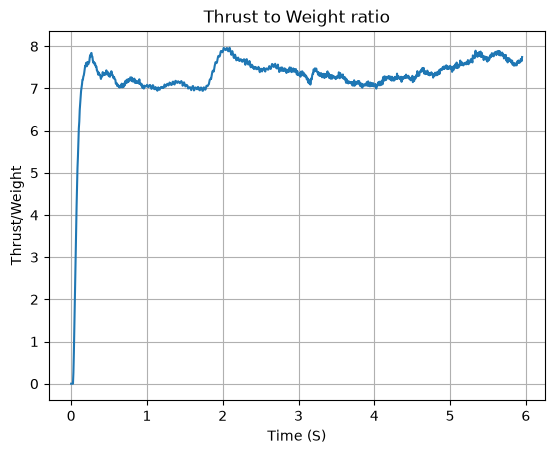

In [73]:
eos.warn_if_unstable()
print(f"CG without motor: {eos.center_of_mass_without_motor} m")
print(f"CG with no propellant: {eos.center_of_dry_mass_position} m")
print(f"CG with propellant: {eos.center_of_mass(0)} m")
if DISPLAY_EXTRA_INFO:
    eos.all_info()
else:
    eos.draw()

In [74]:
flight = Flight(
    rocket=eos,
    environment=env,
    rail_length=launch_data["rail_length"],
    inclination=90-launch_data["rotation_angle"],
    heading=launch_data["heading"],
    terminate_on_apogee=STOP_AT_APOGEE,
    # ode_solver="RK45",
)

Flutter velocity: 1485.4633285945938
Fin's parameters: Surface area (S)=0.0500 m2 | AR=0.392 | λ=0.587 | Thickness=0.01000 m | Shear Modulus (G)=4.830e+06 Pa
Fin Flutter Analysis: Min flutter velocity=49.663 m/s at t=0.00 s | Min flutter Mach=0.148 | Min safety factor=0.157 at t=5.95 s | Altitude of min safety factor=1014.792 m (AGL)


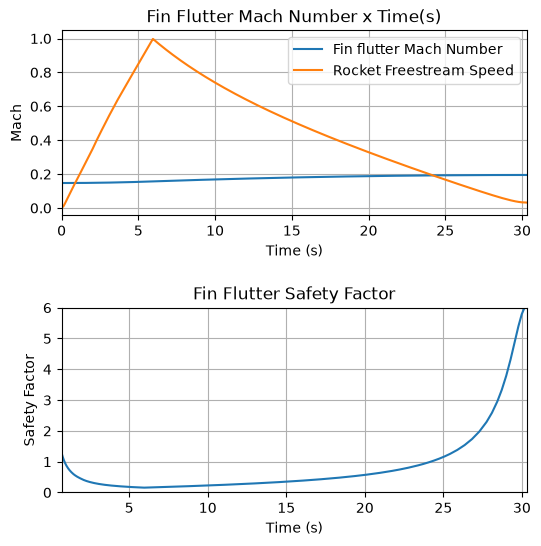

Flutter velocity data from RocketPy: ('Function from R1 to R1 : (Time (s)) → (Mach)', 'Function from R1 to R1 : (Time (s)) → (Safety Factor)')

Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 890.00 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 1.000 | e1: -0.017 | e2: 0.000 | e3: 0.000
Euler Angles - Spin φ : 0.00° | Nutation θ: -2.00° | Precession ψ: 0.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 2.785 c


Surface Wind Conditions

Frontal Surface Wind Speed: 1.00 m/s
Lateral Surface Wind Speed: -2.00 m/s


Launch Rail

Launch Rail Length: 12.192 m
Launch Rail Inclination: 88.00°
Launch Rail Heading: 0.00°


Rail Departure State

Rail Departure Time: 0.699 s
Rail Departure Velocity: 38.685 m/s
Rail Departure Stability Margin: 2.909 c
Rail Departure Angle of Attack: 3.311°
Rail Departure Thrust-Weight Ratio: 7.141
Rail Departure Reynolds Number: 4.124e+05


Burn o

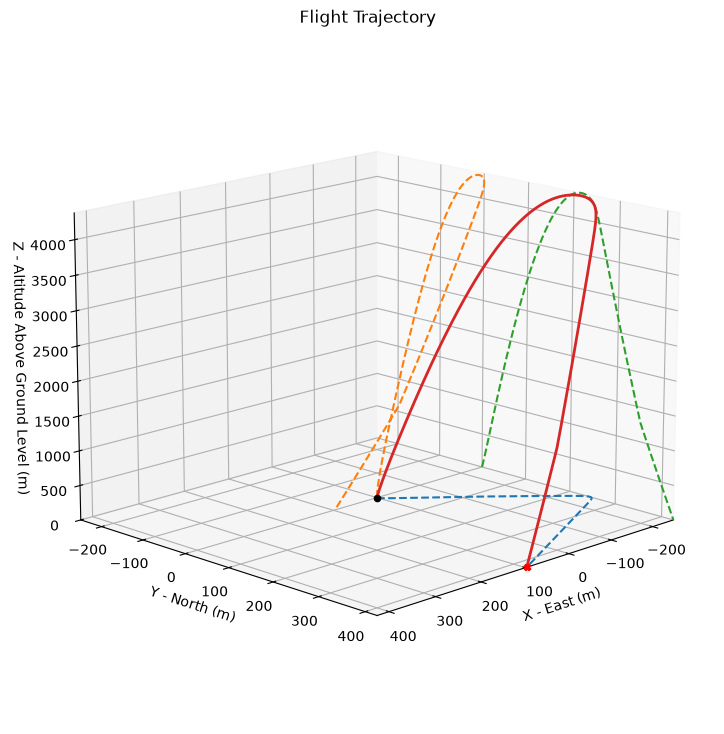



Trajectory Kinematic Plots



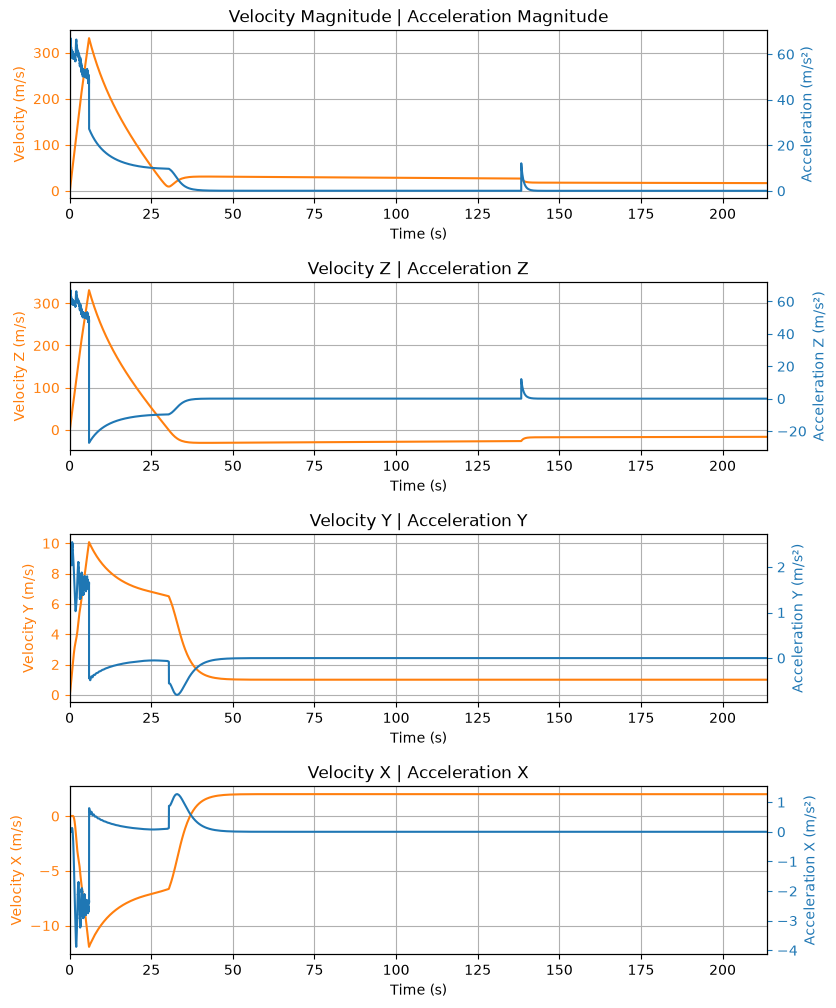



Angular Position Plots



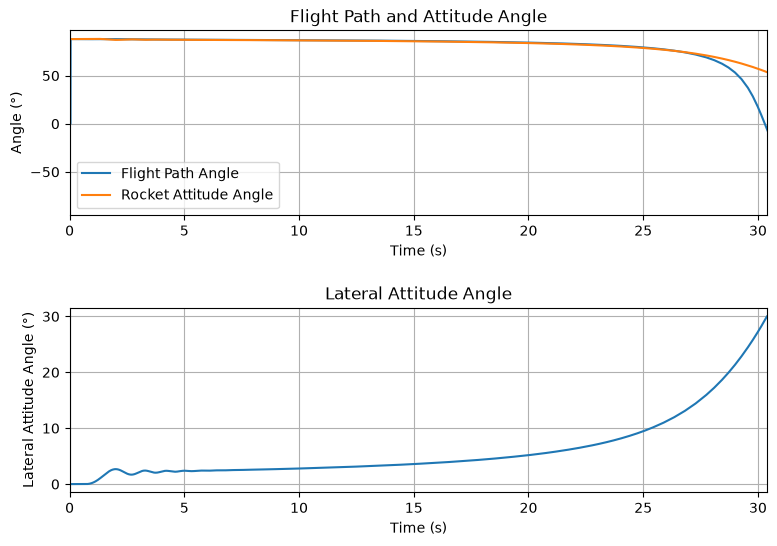



Path, Attitude and Lateral Attitude Angle Plots



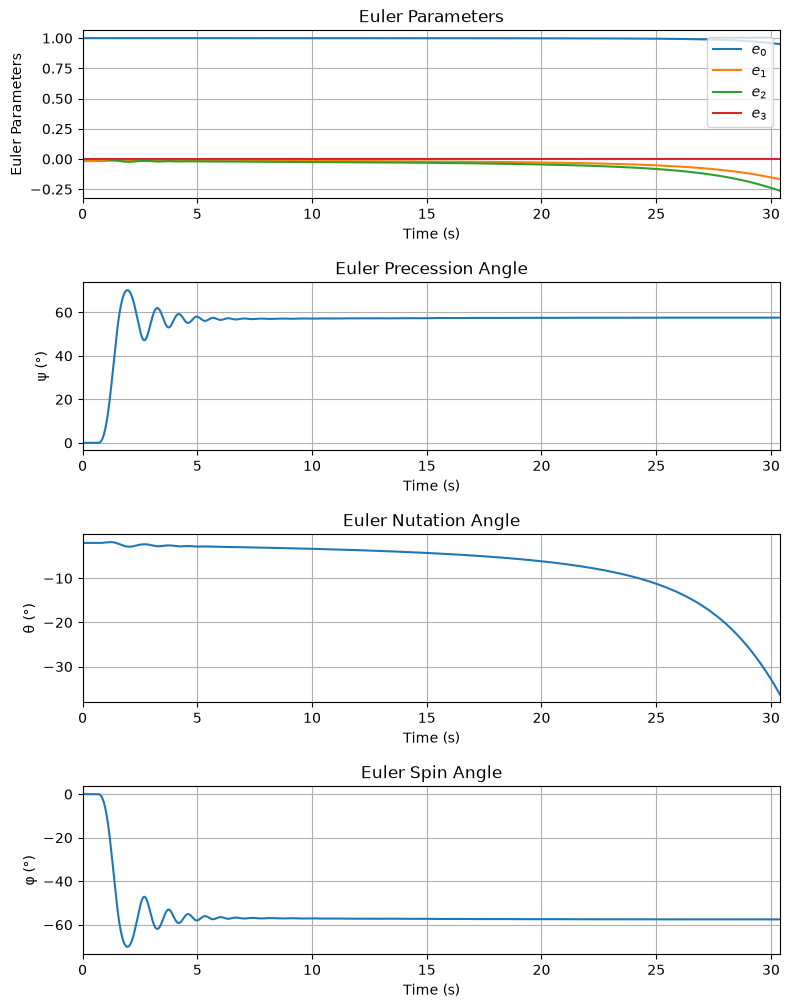



Trajectory Angular Velocity and Acceleration Plots



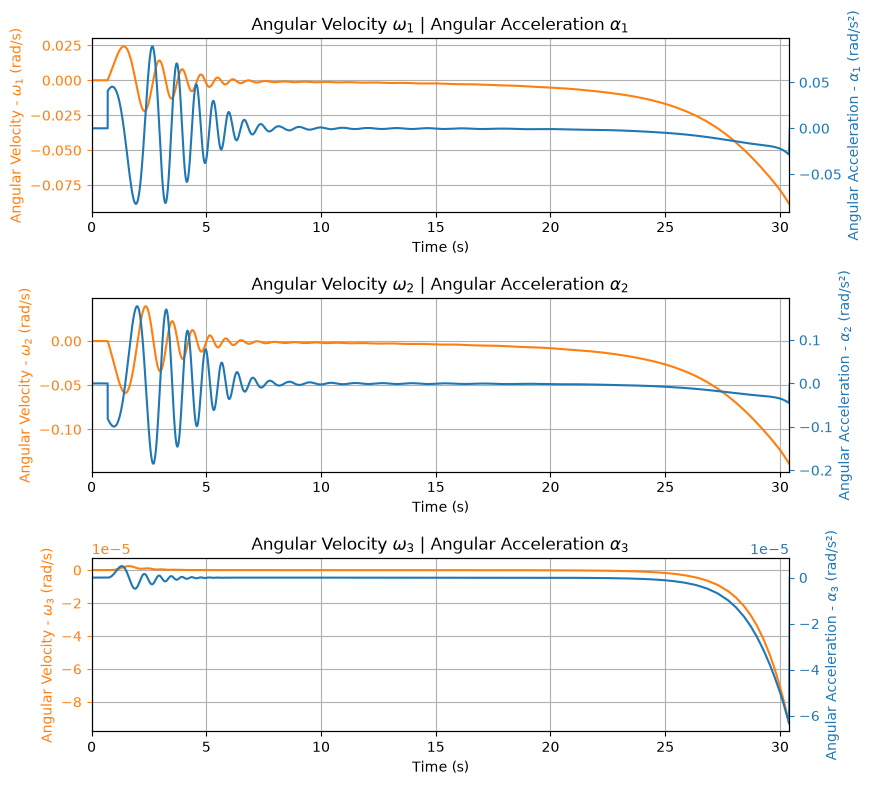



Aerodynamic Forces Plots



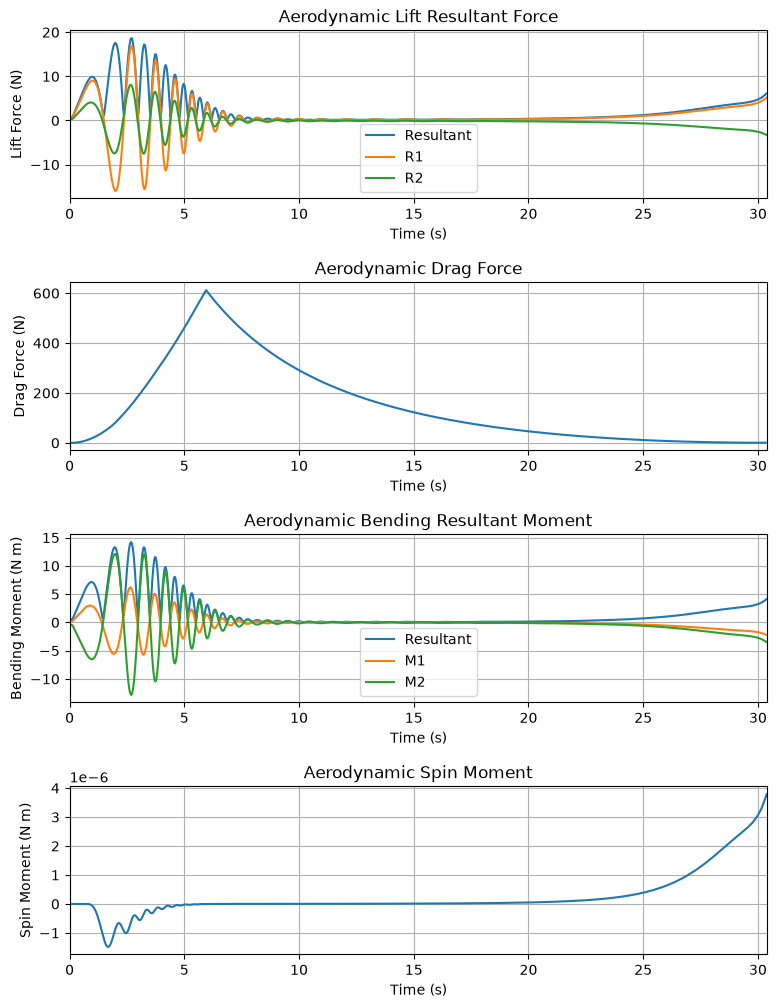

No rail buttons were defined. Skipping rail button bending moment plots.
No rail buttons were defined. Skipping rail button plots.




Rail Buttons Bending Moments Plots



Rail Buttons Forces Plots



Trajectory Energy Plots



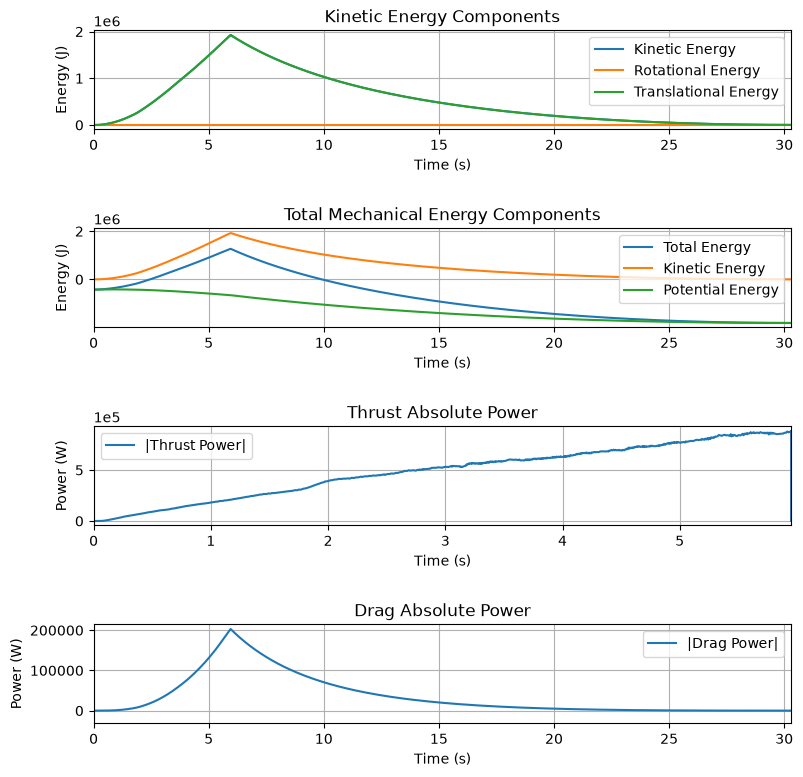



Trajectory Fluid Mechanics Plots



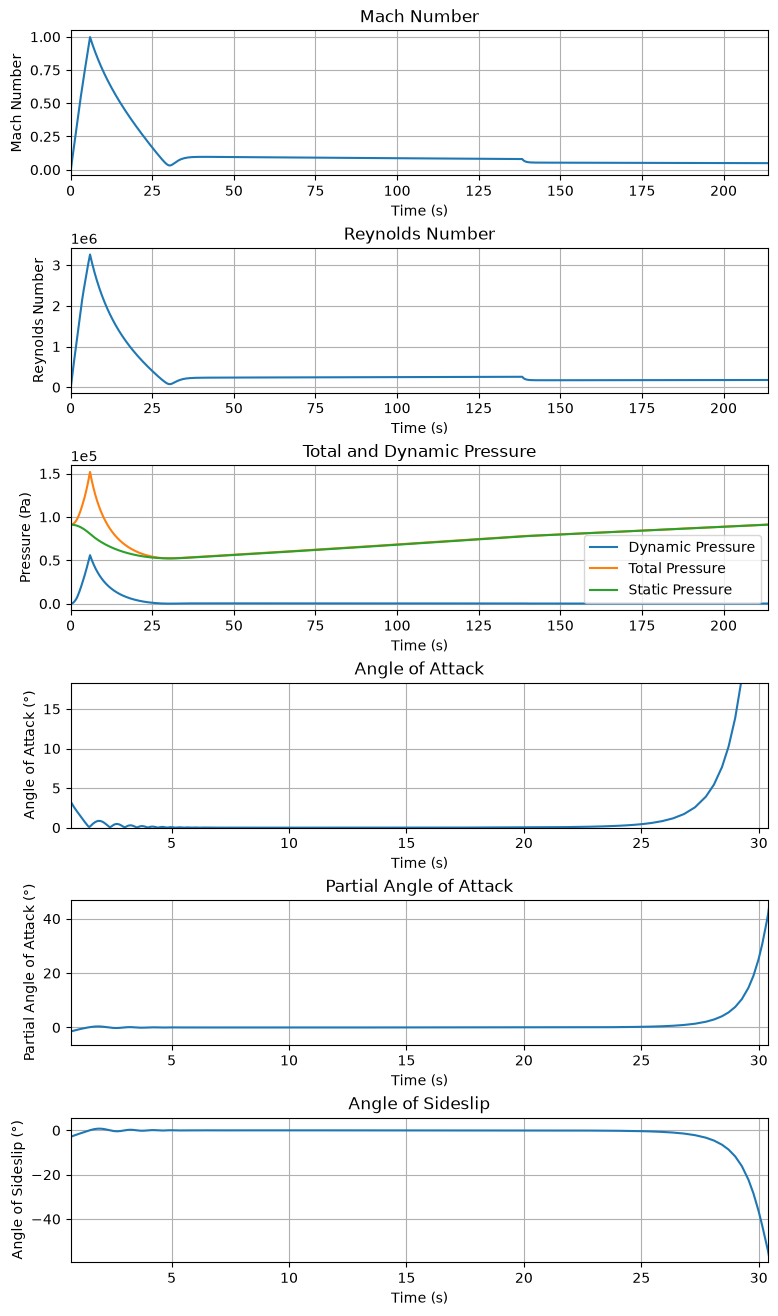



Trajectory Stability and Control Plots



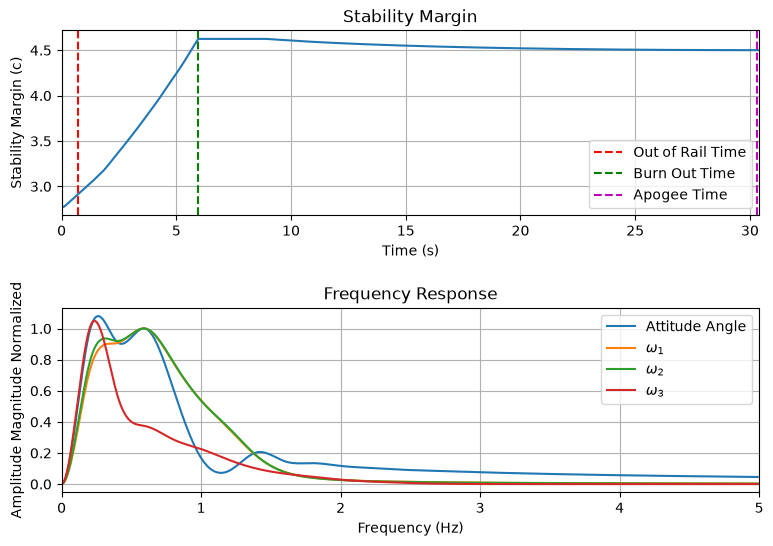



Rocket and Parachute Pressure Plots



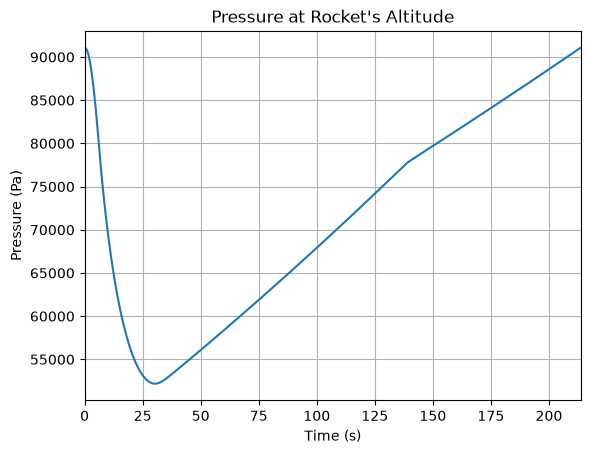

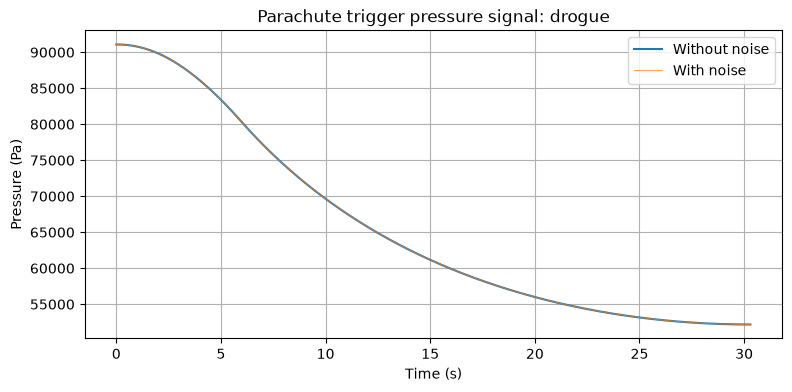

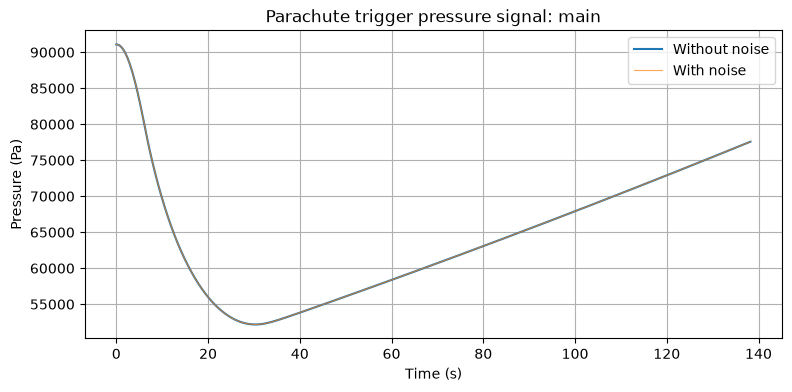

In [ ]:
fin_data = component_data["delta_fins"]
flutter_velocity = get_flutter_velocity(
    aMaxV=flight.altitude(flight.max_speed_time),
    lsa=env.elevation,
    tls=env.temperature(env.elevation) - 273.15, # env.temperature gives a temp in kelvin (need to convert to deg C)
    t=fin_data["thickness"],
    m=fin_data["sweep_length"], # m - From OpenRocket
    tc=fin_data["tip_chord"],
    rc=fin_data["root_chord"],
    ssl=fin_data["span"],
    gE=4.83 * (10 ** 6),
    p0=env.pressure(env.elevation) / 1000, # env.pressure gives pressure in Pa (need to convert to kPa)
    k=1.4, #! temp might need change
    useTipToTip=True,
)
print(f"Flutter velocity: {flutter_velocity}")
data = fin_flutter_analysis(
    fin_thickness=fin_data["thickness"],
    shear_modulus=4.83 * (10 ** 6),
    flight=flight,
    see_prints=True,
    see_graphs=True,
)
del fin_data
if DISPLAY_EXTRA_INFO:
    flight.all_info()
else:
    flight.info()
    flight.plots.trajectory_3d()

In [ ]:
if COMPARISON_SIM_PATH:
    importer = FlightDataImporter(
        paths=COMPARISON_SIM_PATH,
        # Converts column names from OpenRocket to attributes that are available on Flight objects
        columns_map={
            "Time_(s)": "time",
            "Altitude_(m)": "altitude",
            "Altitude_above_sea_level (m)": "z",
            "Latitude_(°_N)": "latitude",
            "Longitude_(°_E)": "longitude",
            "Angle_of_attack_(°)": "angle_of_attack",
            "Vertical_velocity_(m/s)": "vz",
            "Vertical_acceleration_(m/s²)": "az",
            "Total_acceleration_(m/s²)": "acceleration",
            "Position_East_of_launch_(m)": "x",
            "Position_North_of_launch_(m)": "y",
            "Pitch_rate_(rad/s)": "w1",
            "Yaw_rate_(rad/s)": "w2",
            "Roll_rate_(rad/s)": "w3",
            "Stability margin calibers (​)": "stability_margin",
            "Drag_force_(N)": "aerodynamic_drag",
        }
    )
    data_dict = {}
    for attribute in importer.flight_attributes:
        data_dict[attribute] = getattr(importer, attribute)
    comparator = FlightComparator(flight)
    comparator.add_data(COMPARISON_SIM_PATH, data_dict) # For some reason, passing a FlightComparator object directly in doesn't work, so I had to make it manually
    for attribute in importer.flight_attributes:
        if attribute != "time" and hasattr(flight, attribute) and isinstance(getattr(flight, attribute), Function): # Compare all comparable data
            comparator.compare(attribute)
    del data_dict, importer

In [ ]:
if EXPORT_FLIGHT_PATH:
    exporter = FlightDataExporter(flight)
    exporter.export_kml(file_name=EXPORT_FLIGHT_PATH, extrude=True, altitude_mode="relative_to_ground")
    del exporter

In [ ]:
if ANIMATE_TRAJECTORY:
    # This function needs pyvista installed, so running pip install rocketpy[animation]
    # If the play button is not working, change flight_plots.py by adding a line before line 1204 (plotter.add_timer_event) and insert plotter.iren.initialize().
    # flight_plots.py is at path [pathToEnvironment]/Lib/site-packages/rocketpy/plots/flight_plots.py
    flight.plots.animate_trajectory(
        start=0,
        stop=flight.t_final,
        time_step=TIME_STEP,
        playback_speed=PLAYBACK_SPEED,
        background_color="#A8CBE0",
        color_by=COLOR_BY,
        show_kinematic_plots=True,      # altitude, speed and acceleration
        camera_mode=CAMERA_MODE,
        trajectory_line_width=8,        # flown-path width
        show_subrocket_point=True,      # ground projection
        force_external = True,          # force into new window
    )